# Prawo Taylora — analiza wypożyczeń rowerów

Analiza zależności między średnią dzienną liczbą wypożyczeń a jej wariancją dla poszczególnych stacji. Obliczenia obejmują cały zbiór danych oraz osobno weekendy i dni od poniedziałku do piątku.

## Kontekst analizy

Poniżej znajduje się ilustracja wprowadzająca do analizy.


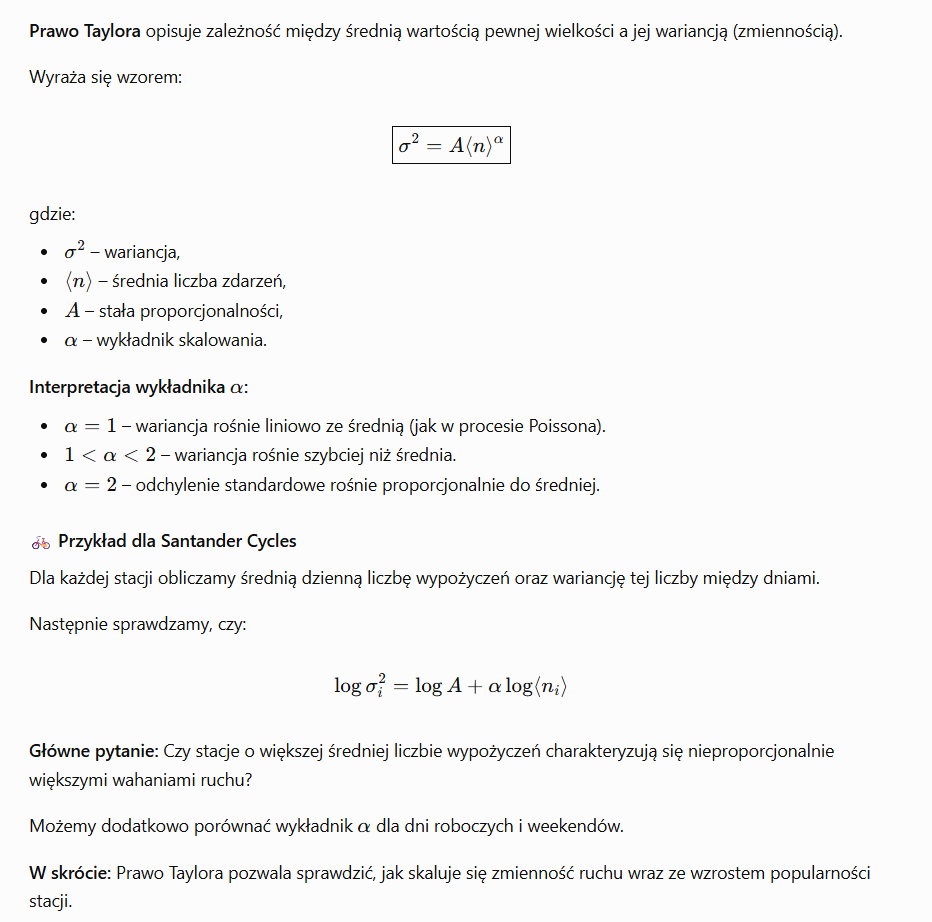

## 4. Binowanie logarytmiczne

Grupujemy stacje według średniej liczby wypożyczeń w przedziałach o kolejnych granicach mnożonych przez `a`. Każdy niepusty bin reprezentuje punkt: średnia geometryczna średnich (`mean_geom`) i średnia geometryczna wariancji (`variance_geom`). `station_count` służy do kontroli liczebności — w późniejszym dopasowaniu każdy bin ma mieć taką samą wagę, niezależnie od liczby stacji. Nie liczymy gęstości ani nie dzielimy przez szerokość przedziału.


In [20]:
def log_binning(mean, variance, a=1.10):
    """Jeden punkt na niepusty bin: średnie geometryczne średnich i wariancji.

    Biny wyznaczamy na osi średniej liczby wypożyczeń.
    Nie dzielimy wyników przez szerokość binu ani liczbę stacji.
    """
    mean = np.asarray(mean, dtype=float)
    variance = np.asarray(variance, dtype=float)

    # Każda średnia musi pozostać sparowana z wariancją tej samej stacji.
    if mean.ndim != 1 or variance.ndim != 1 or mean.shape != variance.shape:
        raise ValueError("Podaj dwie tablice 1D tej samej długości.")
    if not np.isfinite(a) or a <= 1:
        raise ValueError("Współczynnik a musi być skończony i większy od 1.")

    # Logarytmy wymagają dodatnich, skończonych wartości obu współrzędnych.
    valid = (mean > 0) & (variance > 0) & np.isfinite(mean) & np.isfinite(variance)
    print(f"Pominięto {(~valid).sum()} z {len(mean)} par (zera, wartości ujemne, NaN lub inf).")
    mean, variance = mean[valid], variance[valid]
    if mean.size == 0:
        raise ValueError("Brak poprawnych par do binowania.")

    # Kolejne granice rosną geometrycznie: xmin, xmin*a, xmin*a**2, ...
    # Ostatnia granica przekracza maksimum, więc obejmiemy również największe x.
    bin_edges = [mean.min()]
    while bin_edges[-1] <= mean.max():
        bin_edges.append(bin_edges[-1] * a)

    rows = []
    for left, right in zip(bin_edges[:-1], bin_edges[1:]):
        # Przedział [left, right): każda stacja należy dokładnie do jednego binu.
        in_bin = (mean >= left) & (mean < right)
        if not in_bin.any():
            continue

        # Średnia geometryczna = exp(średnia logarytmów).
        rows.append({
            "bin_left": left,
            "bin_right": right,
            "station_count": int(in_bin.sum()),
            "mean_geom": np.exp(np.mean(np.log(mean[in_bin]))),
            "variance_geom": np.exp(np.mean(np.log(variance[in_bin]))),
        })

    return pd.DataFrame(rows)

## 1. Przygotowanie środowiska i danych

### 1.1. Import bibliotek

Biblioteki do obsługi ścieżek, przetwarzania danych, obliczeń numerycznych i tworzenia wykresów.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


def _apply_project_plot_style():
    # Notebooks do not define __file__; start from the working directory.
    current = Path.cwd()
    for path in [current, *current.parents]:
        if (path / "plot_style.py").is_file():
            if str(path) not in sys.path:
                sys.path.insert(0, str(path))

            import plot_style

            plot_style.apply_montserrat_style()
            return

    raise FileNotFoundError("Could not find project plot_style.py")


_apply_project_plot_style()


### 1.2. Wczytanie danych

Odszukanie katalogu projektu zawierającego folder `Data` i wczytanie pliku `rides_data_without_discontinuities.parquet`.


In [2]:
def find_project_root(start=None):
    current = Path.cwd() if start is None else Path(start)
    for path in [current, *current.parents]:
        if (path / "Data").exists():
            return path
    raise FileNotFoundError("Could not find project root containing Data/")


PROJECT_ROOT = find_project_root()
BASE_DIR = PROJECT_ROOT
DATA_DIR = PROJECT_ROOT / "Data"
DATA_FILE = DATA_DIR / "rides_data_without_discontinuities.parquet"
rides_data = pd.read_parquet(DATA_FILE, columns=[
    "start_station_id", "start_station_name", "start_date", "start_day_of_week"
])

### 1.3. Podgląd danych

Pierwsze pięć rekordów pozwala sprawdzić strukturę wczytanej tabeli.


In [3]:
rides_data.head(5)

,start_station_id,start_station_name,start_date,start_day_of_week
0,200254,"Teviot Street, Poplar",2024-01-11 07:48:00,Thursday
1,300048,"Stainsby Road , Poplar",2024-01-11 08:25:00,Thursday
2,300208,"Lavington Street, Bankside",2024-01-11 15:07:00,Thursday
3,200105,"Bonny Street, Camden Town",2024-01-12 10:42:00,Friday
4,1194,"Westminster University, Marylebone",2024-01-13 11:36:00,Saturday


### 1.4. Kontrola okresu obserwacji stacji

Tabela pokazuje pierwsze i ostatnie wypożyczenie, liczbę dni z wypożyczeniami i średnią przed filtrowaniem. Pozostawiamy stacje z wypożyczeniami pierwszego i ostatniego dnia okresu. Tę samą grupę stosujemy na wszystkich wykresach.

**Ograniczenie:** daty przejazdów nie potwierdzają ciągłego działania. Filtr nie wyklucza przerw wewnątrz okresu. Wymagałoby to historii dostępności stacji. Nie wymagamy wypożyczeń każdego dnia, bo brak popytu nie oznacza zamknięcia.

**Ponowna weryfikacja po naprawie dat:** wcześniejsze wyniki dla stacji 2635 oraz 20 brakujących dni pochodziły ze zbioru z błędnie sparsowanymi datami. Surowe CSV zawierają wszystkie 366 dni 2024 roku. Przed interpretacją tabeli należy ponownie wygenerować `final_trip_data.parquet`, następnie `rides_data_without_discontinuities.parquet` i uruchomić ten notebook od początku.


In [4]:
# Keep the original observation calendar before filtering stations.
ride_days = pd.to_datetime(rides_data["start_date"]).dt.normalize()
analysis_days = pd.DatetimeIndex(ride_days.unique()).sort_values()
period_start, period_end = analysis_days.min(), analysis_days.max()
missing_days = pd.date_range(period_start, period_end).difference(analysis_days)

station_coverage = (
    rides_data.assign(day=ride_days)
    .groupby("start_station_id")
    .agg(station_name=("start_station_name", "first"),
         first_observed=("day", "min"), last_observed=("day", "max"),
         days_with_rentals=("day", "nunique"), total_rentals=("day", "size"))
)
station_coverage["mean_before_filter"] = station_coverage["total_rentals"] / len(analysis_days)
station_coverage["observed_at_both_boundaries"] = (
    station_coverage["first_observed"].eq(period_start)
    & station_coverage["last_observed"].eq(period_end)
)
print(f"Period: {period_start.date()} to {period_end.date()}")
print(f"Observed days: {len(analysis_days)}; missing calendar days: {len(missing_days)}")
print("Missing dates:", missing_days.strftime("%Y-%m-%d").tolist())
display(station_coverage.nsmallest(10, "mean_before_filter"))

eligible_station_ids = station_coverage.index[station_coverage["observed_at_both_boundaries"]]
print(f"Stations retained: {len(eligible_station_ids)} / {len(station_coverage)}")
rides_data = rides_data[rides_data["start_station_id"].isin(eligible_station_ids)].copy()


Period: 2024-01-01 to 2025-12-31
Observed days: 731; missing calendar days: 0
Missing dates: []


,station_name,first_observed,last_observed,days_with_rentals,total_rentals,mean_before_filter,observed_at_both_boundaries
start_station_id,,,,,,,
2635,"Agar Grove, Camden Town",2025-12-25,2025-12-31,7,25,0.034200,False
300099,"Adeline Place, Bloomsbury",2025-10-29,2025-12-31,62,832,1.138167,False
1111,"St. Pancras Way, Camden Town",2025-05-05,2025-12-31,231,1683,2.302326,False
300084,"Sirdar Road, Avondale",2024-01-01,2025-12-31,709,3109,4.253078,True
1212,"Concert Hall Approach, South Bank",2025-08-18,2025-12-31,136,3141,4.296854,False
200224,"Colet Gardens, Hammersmith",2024-01-01,2025-12-31,709,3196,4.372093,True
200138,"Heron Quays DLR, Canary Wharf",2024-01-01,2025-12-31,680,3265,4.466484,True
1069,"Eaton Square, Belgravia",2024-01-01,2025-12-31,335,3464,4.738714,True
200233,"South Quay East, Canary Wharf",2024-01-01,2025-12-31,676,3561,4.871409,True


Stations retained: 751 / 801


## 2. Prawo Taylora dla całego zbioru danych


### 2.1. Dzienna liczba wypożyczeń — średnia i wariancja

Dla każdej stacji wyznaczamy dzienne liczebności, a następnie średnią i wariancję. Dzielnikiem jest liczba różnych dat obecnych w analizowanym zbiorze; brak wypożyczeń ze stacji w takim dniu odpowiada zerowej liczebności.


In [5]:
# Liczba wypozyczen dla kazdej stacji i kazdego dnia.
start_days = pd.to_datetime(rides_data["start_date"]).dt.normalize()

observed_counts = (
    rides_data.groupby(["start_station_id", start_days])
    .size()
    .reset_index(name="count")
)

# Srednia dzienna liczba wypozyczen dla kazdej stacji.
mean_counts = (
    observed_counts.groupby("start_station_id")["count"]
    .sum()
    .div(len(analysis_days))
    .reset_index(name="mean_count")
)

# Suma kwadratów dziennych liczebności dla każdej stacji.
sum_sq = (
    observed_counts.groupby("start_station_id")["count"]
    .apply(lambda x: (x**2).sum())
)

# Wariancja dziennej liczby wypożyczeń.
mean_counts["variance"] = (
    mean_counts["start_station_id"].map(sum_sq) / len(analysis_days)
    - mean_counts["mean_count"]**2
)

mean_counts.head()

,start_station_id,mean_count,variance
0,959,25.882353,106.205037
1,960,95.320109,878.198488
2,961,26.719562,120.464446
3,962,27.616963,212.118673
4,963,32.125855,151.923969


### 2.2. Dopasowanie prawa Taylora i wykres

Dopasowujemy zależność $\mathrm{Var}(X) = \mathrm{E}(X)^{\alpha}$. Współczynnik $\alpha$ jest wyznaczany w skali logarytmicznej przy wyrazie wolnym równym zero. Wykres przedstawia stacje i dopasowaną zależność na osiach logarytmicznych.


In [ ]:
MIN_STATIONS_PER_BIN = 5

# Binowanie wykonujemy RAZ — oba dopasowania korzystają z tych samych przedziałów.
log_binned = log_binning(mean_counts["mean_count"], mean_counts["variance"], a=1.15)
log_binned_min5 = log_binned.loc[
    log_binned["station_count"] >= MIN_STATIONS_PER_BIN
]


def fit_binned_alpha(bins):
    """Prosta bez wyrazu wolnego w skali log; każdy bin ma równą wagę."""
    if len(bins) < 2:
        return np.nan  # Za mało punktów do porównania dopasowań.
    log_x = np.log10(bins["mean_geom"].to_numpy())
    log_y = np.log10(bins["variance_geom"].to_numpy())
    denominator = np.sum(log_x**2)
    return np.sum(log_x * log_y) / denominator if denominator > 0 else np.nan


alpha = fit_binned_alpha(log_binned)
alpha_min5 = fit_binned_alpha(log_binned_min5)

# Porównujemy również utratę stacji i zakresu X, szczególnie na ogonach chmury.
fit_comparison = pd.DataFrame([
    {
        "wariant": name,
        "liczba_binow": len(bins),
        "liczba_stacji": int(bins["station_count"].sum()),
        "x_min": bins["mean_geom"].min(),
        "x_max": bins["mean_geom"].max(),
        "alpha": exponent,
    }
    for name, bins, exponent in [
        ("Wszystkie niepuste biny", log_binned, alpha),
        (f"Biny: min. {MIN_STATIONS_PER_BIN} stacji", log_binned_min5, alpha_min5),
    ]
])
display(fit_comparison)
if np.isfinite(alpha) and np.isfinite(alpha_min5):
    print(f"Zmiana alfa (min. {MIN_STATIONS_PER_BIN} stacji minus wszystkie): "
          f"{alpha_min5 - alpha:+.4f}")
else:
    print("Brak poprawnego dopasowania w co najmniej jednym wariancie "
          "(za mało binów lub wszystkie średnie geometryczne równe 1).")

fig, ax = plt.subplots(figsize=(10, 7))

valid = (
    (mean_counts["mean_count"] > 0) & (mean_counts["variance"] > 0)
    & np.isfinite(mean_counts["mean_count"]) & np.isfinite(mean_counts["variance"])
)
ax.scatter(
    mean_counts.loc[valid, "mean_count"], mean_counts.loc[valid, "variance"],
    s=25, color="#2474B5", alpha=0.65, edgecolors="none",
    label="Stacje", zorder=1,
)

# Czarne romby: wszystkie biny; pomarańczowe obwódki: biny spełniające próg.
ax.scatter(
    log_binned["mean_geom"], log_binned["variance_geom"],
    marker="D", s=52, color="#111111", alpha=0.85,
    edgecolors="white", linewidths=0.7, label="Wszystkie niepuste biny", zorder=4,
)
if not log_binned_min5.empty:
    ax.scatter(
        log_binned_min5["mean_geom"], log_binned_min5["variance_geom"],
        marker="D", s=88, facecolors="none", edgecolors="#D55E00", linewidths=1.3,
        label=f"Biny: min. {MIN_STATIONS_PER_BIN} stacji", zorder=5,
    )

# Każdą linię rysujemy tylko w zakresie binów użytych w danym dopasowaniu.
for bins, exponent, color, linestyle, label in [
    (log_binned, alpha, "black", "-", "Wszystkie biny"),
    (log_binned_min5, alpha_min5, "#D55E00", "--", f"Min. {MIN_STATIONS_PER_BIN} stacji"),
]:
    if np.isfinite(exponent):
        x_fit = np.geomspace(bins["mean_geom"].min(), bins["mean_geom"].max(), 200)
        ax.plot(
            x_fit, x_fit**exponent, color=color, linestyle=linestyle, linewidth=2,
            label=rf"{label}: alpha = {exponent:.3f}$", zorder=3,
        )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Średnia dzienna liczba wypożyczeń")
ax.set_ylabel("Wariancja")
ax.set_title("Prawo Taylora — porównanie liczebności binów")
ax.set_axisbelow(True)
ax.grid(which="major", alpha=0.30, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="best", fontsize=9)
fig.tight_layout()
plt.show()


Pominięto 0 z 751 par (zera, wartości ujemne, NaN lub inf).


,wariant,liczba_binow,liczba_stacji,x_min,x_max,alpha
0,Wszystkie niepuste biny,25,751,4.591823,153.132695,1.534397
1,Biny: min. 5 stacji,20,739,4.591823,85.274854,1.464459


Zmiana alfa (min. 5 stacji minus wszystkie): -0.0699


ValueError: 
Wszystkie biny: $lpha = 1.534$
                ^
ParseException: Expected end of text, found '$'  (at char 16), (line:1, col:17)

Error in callback <function _draw_all_if_interactive at 0x00000268E645A520> (for post_execute), with arguments args (),kwargs {}:


ValueError: 
Wszystkie biny: $lpha = 1.534$
                ^
ParseException: Expected end of text, found '$'  (at char 16), (line:1, col:17)

ValueError: 
Wszystkie biny: $lpha = 1.534$
                ^
ParseException: Expected end of text, found '$'  (at char 16), (line:1, col:17)

<Figure size 1800x1260 with 1 Axes>

## 3. Porównanie weekendów i dni od poniedziałku do piątku

W obu grupach stosujemy tę samą metodę obliczania statystyk i dopasowania wykładnika prawa Taylora.


### 3.1. Podział danych

Weekendy obejmują soboty i niedziele, a druga grupa — dni od poniedziałku do piątku, bez osobnego wyłączenia świąt.


In [7]:
rides_data_weekends = rides_data[rides_data["start_day_of_week"].isin(["Saturday", "Sunday"])]
rides_data_weekdays = rides_data[rides_data["start_day_of_week"].isin(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])]

### 3.2. Weekendy


#### Statystyki dzienne dla stacji

Średnią i wariancję obliczamy analogicznie jak dla całego zbioru, uwzględniając wyłącznie daty weekendowe obecne w danych.


In [8]:
# Liczba wypozyczen dla kazdej stacji i kazdego dnia.
start_days_weekends = pd.to_datetime(rides_data_weekends["start_date"]).dt.normalize()

observed_counts_weekends = (
    rides_data_weekends.groupby(["start_station_id", start_days_weekends])
    .size()
    .reset_index(name="count")
)

# Srednia dzienna liczba wypozyczen dla kazdej stacji.
mean_counts_weekends = (
    observed_counts_weekends.groupby("start_station_id")["count"]
    .sum()
    .div(len(analysis_days[analysis_days.dayofweek >= 5]))
    .reset_index(name="mean_count")
)

# Suma kwadratów dziennych liczebności dla każdej stacji.
sum_sq_weekends = (
    observed_counts_weekends.groupby("start_station_id")["count"]
    .apply(lambda x: (x**2).sum())
)

# Wariancja dziennej liczby wypożyczeń.
mean_counts_weekends["variance"] = (
    mean_counts_weekends["start_station_id"].map(sum_sq_weekends) / len(analysis_days[analysis_days.dayofweek >= 5])
    - mean_counts_weekends["mean_count"]**2
)

mean_counts_weekends.head()

,start_station_id,mean_count,variance
0,959,19.307692,53.107249
1,960,84.500000,862.557692
2,961,17.177885,46.867396
3,962,15.427885,37.312107
4,963,22.600962,78.028268


#### Dopasowanie i wizualizacja

Wyznaczamy wykładnik $\alpha$ dla weekendów i przedstawiamy zależność wariancji od średniej.


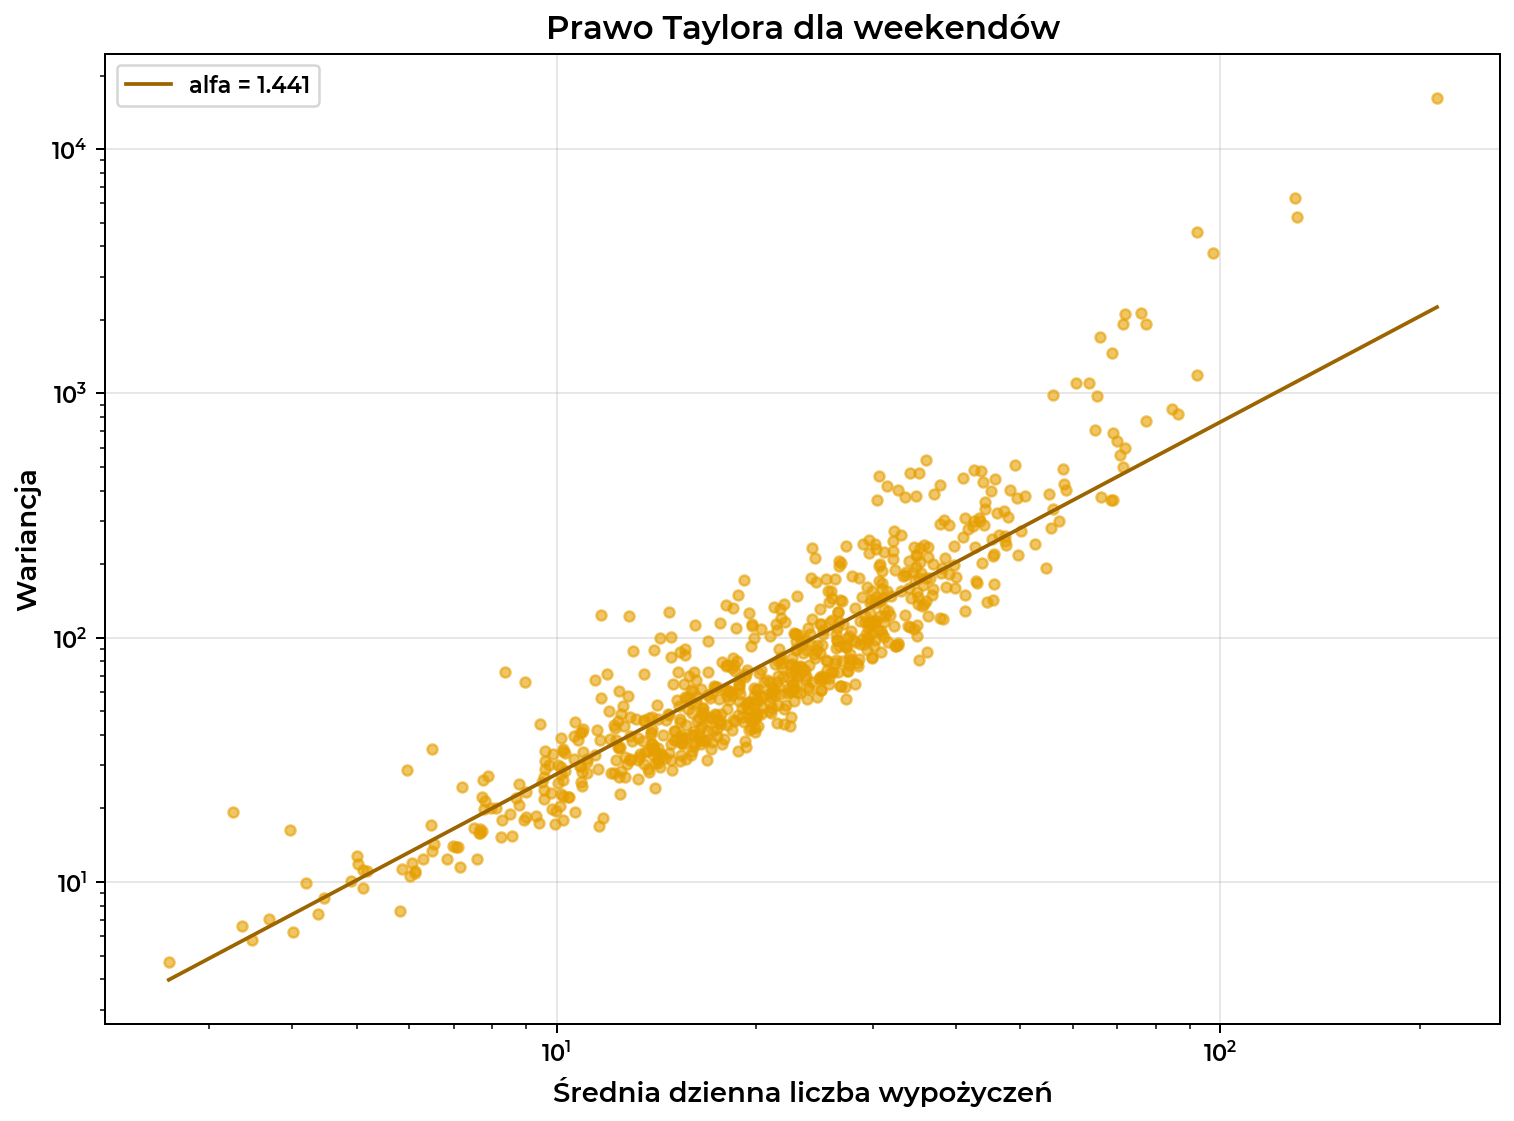

In [9]:
plt.figure(figsize=(10, 7))

x = mean_counts_weekends["mean_count"]
y = mean_counts_weekends["variance"]

log_x_weekends = np.log10(x)
log_y_weekends = np.log10(y)
alpha_weekends = np.sum(log_x_weekends * log_y_weekends) / np.sum(log_x_weekends**2)

plt.plot(
    mean_counts_weekends["mean_count"],
    mean_counts_weekends["variance"],
    "o",
    markersize=4,
    color="#E69F00",
    alpha=0.6
)
# Dopasowana prosta
x_fit = np.linspace(x.min(), x.max())
plt.plot(x_fit, x_fit**alpha_weekends, color="#9C6500", label=f"alfa = {alpha_weekends:.3f}")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Średnia dzienna liczba wypożyczeń")
plt.ylabel("Wariancja")
plt.title("Prawo Taylora dla weekendów")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### 3.3. Dni od poniedziałku do piątku


#### Statystyki dzienne dla stacji

Średnią i wariancję obliczamy dla dat od poniedziałku do piątku obecnych w tej części danych.


In [10]:
# Liczba wypozyczen dla kazdej stacji i kazdego dnia.
start_days_weekdays = pd.to_datetime(rides_data_weekdays["start_date"]).dt.normalize()

observed_counts_weekdays = (
    rides_data_weekdays.groupby(["start_station_id", start_days_weekdays])
    .size()
    .reset_index(name="count")
)

# Srednia dzienna liczba wypozyczen dla kazdej stacji.
mean_counts_weekdays = (
    observed_counts_weekdays.groupby("start_station_id")["count"]
    .sum()
    .div(len(analysis_days[analysis_days.dayofweek < 5]))
    .reset_index(name="mean_count")
)

# Suma kwadratów dziennych liczebności dla każdej stacji.
sum_sq_weekdays = (
    observed_counts_weekdays.groupby("start_station_id")["count"]
    .apply(lambda x: (x**2).sum())
)

# Wariancja dziennej liczby wypożyczeń.
mean_counts_weekdays["variance"] = (
    mean_counts_weekdays["start_station_id"].map(sum_sq_weekdays) / len(analysis_days[analysis_days.dayofweek < 5])
    - mean_counts_weekdays["mean_count"]**2
)

mean_counts_weekdays.head()

,start_station_id,mean_count,variance
0,959,28.497132,103.293969
1,960,99.623327,819.339953
2,961,30.514340,99.125511
3,962,32.464627,199.051808
4,963,35.913958,130.881698


#### Dopasowanie i wizualizacja

Wyznaczamy wykładnik $\alpha$ dla dni od poniedziałku do piątku. Wynik można porównać z wykresem weekendowym i analizą całego zbioru.


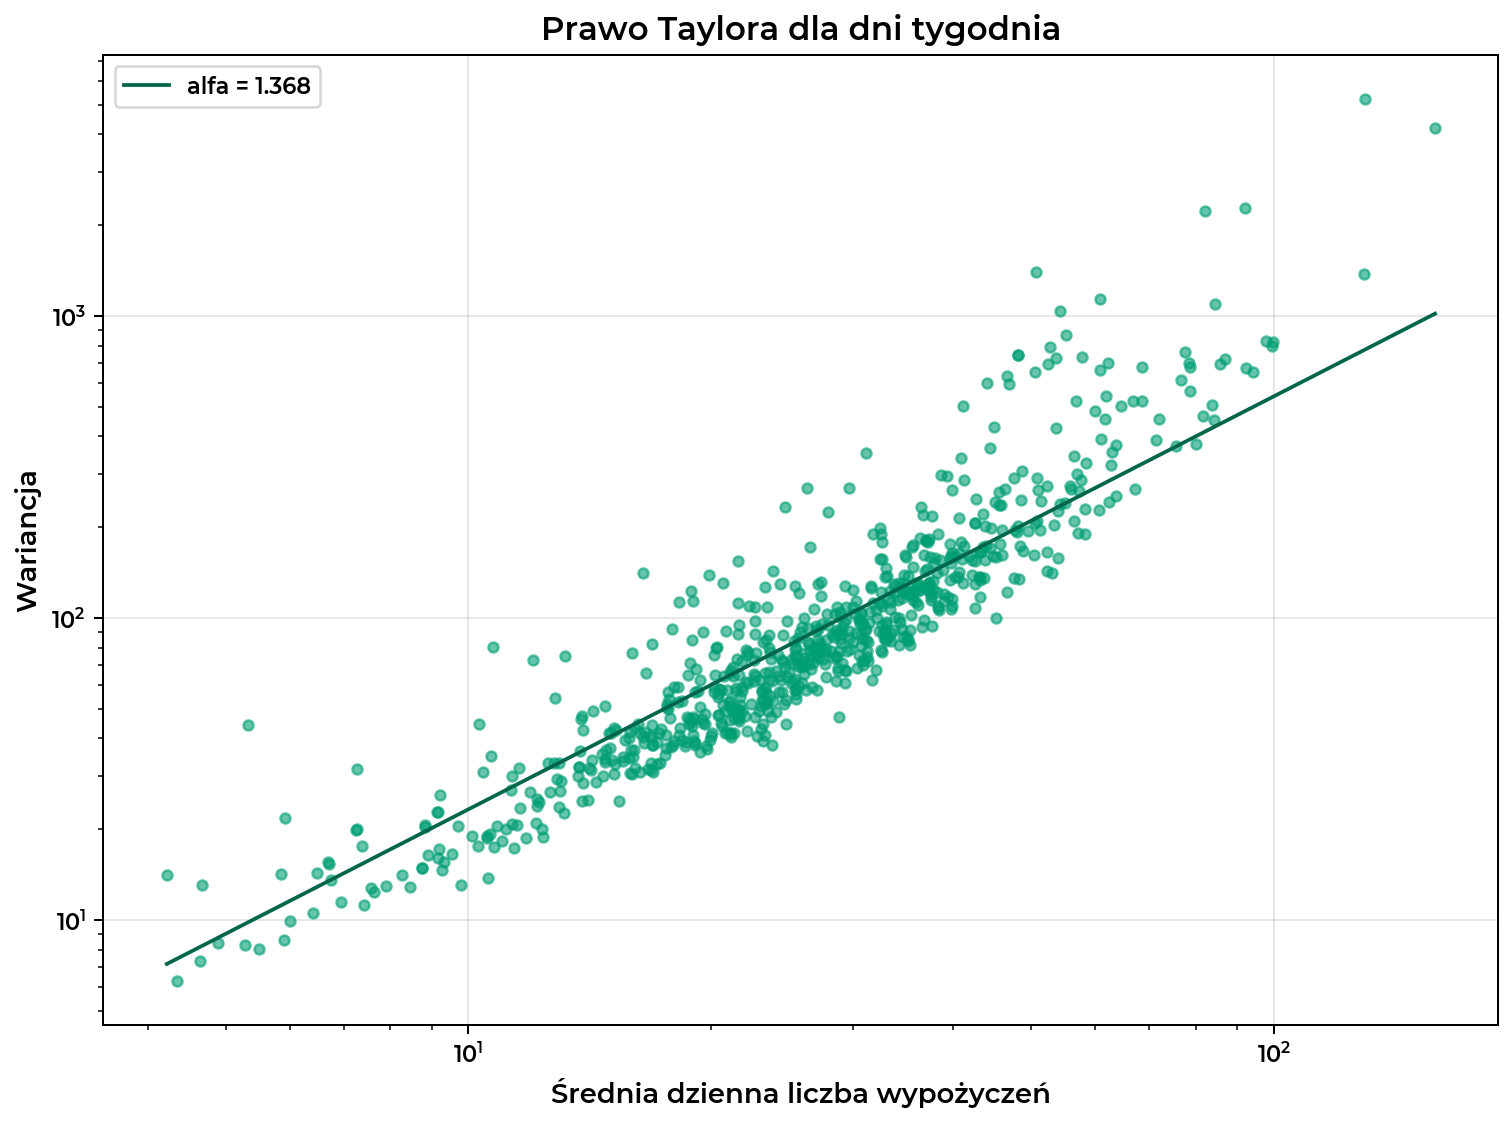

In [11]:
plt.figure(figsize=(10, 7))

x = mean_counts_weekdays["mean_count"]
y = mean_counts_weekdays["variance"]

log_x_weekdays = np.log10(x)
log_y_weekdays = np.log10(y)
alpha_weekdays = np.sum(log_x_weekdays * log_y_weekdays) / np.sum(log_x_weekdays**2)

plt.plot(
    mean_counts_weekdays["mean_count"],
    mean_counts_weekdays["variance"],
    "o",
    markersize=4,
    color="#009E73",
    alpha=0.6
)
# Dopasowana prosta
x_fit = np.linspace(x.min(), x.max())
plt.plot(x_fit, x_fit**alpha_weekdays, color="#00664B", label=f"alfa = {alpha_weekdays:.3f}")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Średnia dzienna liczba wypożyczeń")
plt.ylabel("Wariancja")
plt.title("Prawo Taylora dla dni tygodnia")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## Prawo Taylora dla wybranego miesiąca - maj 2025

In [14]:
rides_data["start_date"] = pd.to_datetime(
    rides_data["start_date"]
).dt.normalize()

rides_data_may_2025 = rides_data[
    (rides_data["start_date"] >= "2025-05-01")
    & (rides_data["start_date"] < "2025-06-01")
]

daily_counts_may = (
    rides_data_may_2025
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=rides_data["start_station_id"].dropna().unique(),
        columns=pd.date_range("2025-05-01", "2025-05-31"),
        fill_value=0,
    )
)

mean_counts_may_2025 = pd.DataFrame({
    "mean_count": daily_counts_may.mean(axis=1),
    "variance": daily_counts_may.var(axis=1, ddof=0),
}).rename_axis("start_station_id").reset_index()

mean_counts_may_2025.head()

,start_station_id,mean_count,variance
0,200254,5.645161,8.616025
1,300048,25.000000,43.548387
2,300208,24.935484,55.931322
3,200105,49.677419,136.670135
4,1194,22.774194,52.174818


Stacje na wykresie: 750 / 751; pominięte: 1 (zerowa średnia/wariancja lub brak skończonej wartości).


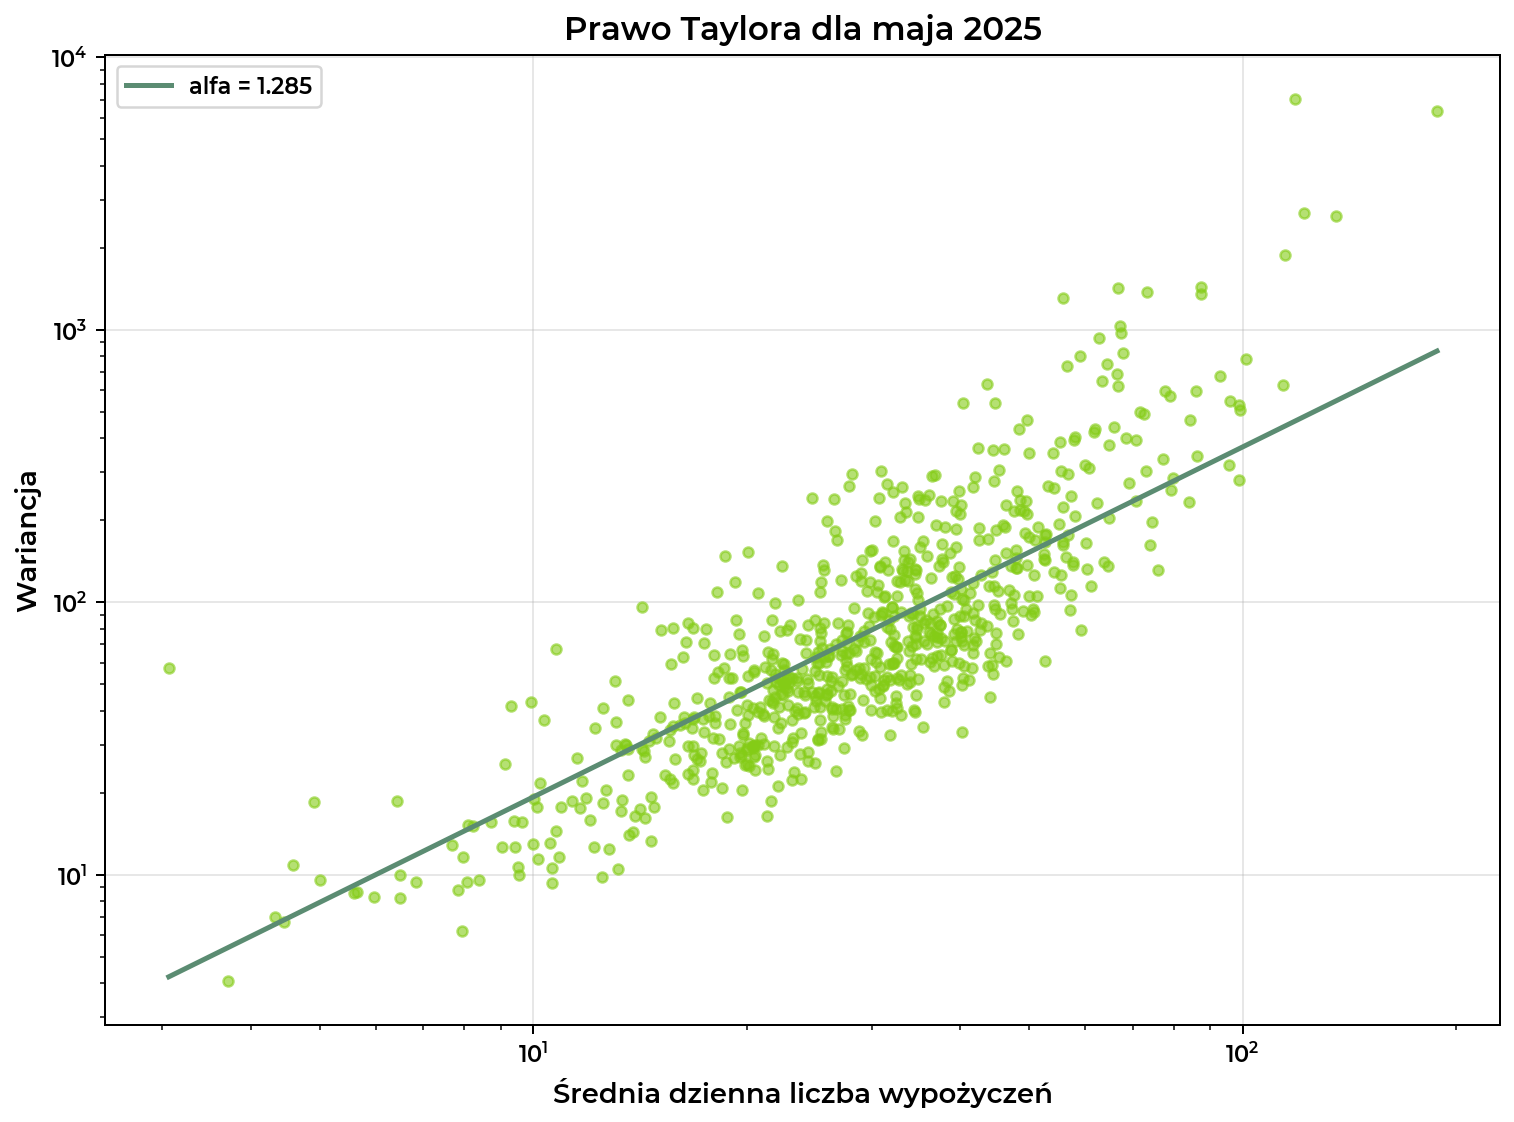

In [17]:
# Logarithms require positive, finite means and variances.
if mean_counts_may_2025["variance"].lt(0).any():
    raise ValueError("Negative variance: check the daily count calculations.")

valid_may = (
    mean_counts_may_2025["mean_count"].gt(0)
    & mean_counts_may_2025["variance"].gt(0)
    & np.isfinite(mean_counts_may_2025["mean_count"])
    & np.isfinite(mean_counts_may_2025["variance"])
)
may_plot_data = mean_counts_may_2025.loc[valid_may]
print(f"Stacje na wykresie: {len(may_plot_data)} / {len(mean_counts_may_2025)}; "
      f"pominięte: {(~valid_may).sum()} (zerowa średnia/wariancja lub brak skończonej wartości).")

x = may_plot_data["mean_count"].to_numpy()
y = may_plot_data["variance"].to_numpy()
if len(x) < 2:
    raise ValueError("At least two stations with positive mean and variance are required.")

log_x_may_2025 = np.log10(x)
log_y_may_2025 = np.log10(y)
denominator_may = np.sum(log_x_may_2025**2)
if denominator_may == 0:
    raise ValueError("Cannot fit alpha: all retained mean counts equal one.")
alpha_may_2025 = np.sum(log_x_may_2025 * log_y_may_2025) / denominator_may

plt.figure(figsize=(10, 7))
plt.plot(x, y, "o", markersize=4, color="#84CC16", alpha=0.6)

x_fit = np.geomspace(x.min(), x.max(), 200)
plt.plot(x_fit, x_fit**alpha_may_2025, color="#5B8C72", linewidth=2,
         label=f"alfa = {alpha_may_2025:.3f}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Średnia dzienna liczba wypożyczeń")
plt.ylabel("Wariancja")
plt.title("Prawo Taylora dla maja 2025")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Pigułka — co policzyliśmy?

Z danych przejazdów bez nieciągłości stacji wyznaczyliśmy dzienne liczby wypożyczeń dla każdej stacji. Wybraliśmy **751 z 801 stacji**, które miały wypożyczenia pierwszego i ostatniego dnia okresu 2024–2025; zachowaliśmy **95,69% przejazdów**. To kryterium obecności w danych, nie gwarancja ciągłego działania stacji.

Porównaliśmy zależność wariancji od średniej dla całego okresu, weekendów, dni od poniedziałku do piątku i **maja 2025**. Każdy punkt na wykresie to jedna stacja.

Dla stacji $i$, dziennej liczby wypożyczeń $n_{i,d}$ i $N$ dni wybranego zakresu liczyliśmy:

$$
\mu_i = \frac{1}{N}\sum_{d=1}^{N} n_{i,d},
\qquad
v_i = \frac{1}{N}\sum_{d=1}^{N}(n_{i,d}-\mu_i)^2
= \frac{1}{N}\sum_{d=1}^{N}n_{i,d}^2-\mu_i^2.
$$

Uwzględnialiśmy dni bez wypożyczeń jako zera. W analizach całego okresu i typów dni używaliśmy wspólnego kalendarza dat obecnych w zbiorze przed filtrowaniem stacji; dla maja $N=31$. Wariancja jest populacyjna (`ddof=0`).

Dopasowywaliśmy uproszczone prawo Taylora $v_i=\mu_i^{\alpha}$, czyli ze współczynnikiem proporcjonalności równym $1$:

$$
\log_{10}v_i=\alpha\log_{10}\mu_i,
\qquad
\hat{\alpha}=\frac{\sum_i(\log_{10}\mu_i)(\log_{10}v_i)}{\sum_i(\log_{10}\mu_i)^2}.
$$

To dopasowanie metodą najmniejszych kwadratów **bez wyrazu wolnego** w skali logarytmicznej. Logarytmy wymagają dodatnich, skończonych średnich i wariancji — w majowym dopasowaniu pomijamy pozostałe stacje, pozostawiając je w tabeli statystyk.
